# Group 5 final project
## Project description
**Goal**:


## Load data
### About our data

In [9]:
import pandas as pd

otu_table = pd.read_csv('otu_table.txt', delimiter='\t', index_col=0)

meta_data = pd.read_csv('sample_data.txt', delimiter='\t', index_col=0)

tax_table = pd.read_csv('tax_table.txt', delimiter='\t', index_col=0)

print(f"OTU shape: {otu_table.shape}, Metadata shape: {meta_data.shape}, Tax shape: {tax_table.shape}")


OTU shape: (718, 616), Metadata shape: (616, 22), Tax shape: (718, 7)


In [10]:
print("Total samples:", len(meta_data))
print("Unique subject_ids:", meta_data["subject_id"].nunique())

# View duplicated subject_ids or rows with missing study_condition
extra_rows = meta_data[meta_data.duplicated("subject_id", keep=False) | meta_data["study_condition"].isna()]

# Keep 1 sample per unique subject_id (keeps the first occurrence; sort by 'number_reads' first if you prefer highest depth)
meta_616 = meta_data.drop_duplicates(subset="subject_id", keep="first")

# Subset and align the OTU table columns to match the 616 sample IDs
otu_616 = otu_table[meta_616.index]

print("Filtered shapes -> OTU:", otu_616.shape, "| Meta:", meta_616.shape)

Total samples: 616
Unique subject_ids: 616
Filtered shapes -> OTU: (718, 616) | Meta: (616, 22)


## Exploratory data analysis

--- Study Condition Counts ---
study_condition
CRC                          258
control                      251
adenoma                       67
carcinoma_surgery_history     40
Name: count, dtype: int64
--- Disease status counts ---
disease
CRC                          258
healthy                      246
adenoma                       67
carcinoma_surgery_history     40
few_polyps                     5
Name: count, dtype: int64

--- Numeric Metadata Summary ---
              age         BMI  number_reads
count  616.000000  615.000000  6.160000e+02
mean    61.759740   22.839519  4.471294e+07
std     11.115684    3.359602  1.276635e+07
min     21.000000   16.141529  7.222700e+05
25%     55.000000   20.616192  3.696987e+07
50%     64.000000   22.506925  4.386607e+07
75%     70.000000   24.609375  5.158936e+07
max     79.000000   49.535132  1.013650e+08


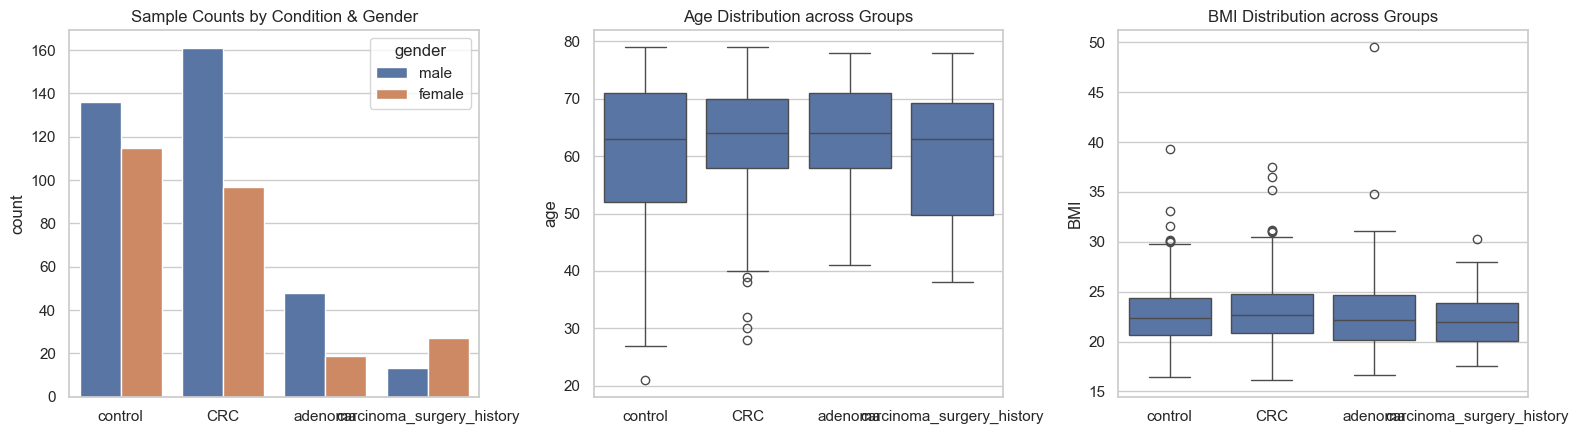

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

# 1. Inspect group counts and summary statistics
print("--- Study Condition Counts ---")
print(meta_616["study_condition"].value_counts(dropna=False))

print("--- Disease status counts ---")
print(meta_616["disease"].value_counts(dropna=False))

print("\n--- Numeric Metadata Summary ---")
print(meta_616[["age", "BMI", "number_reads"]].describe())

# 2. Plot metadata distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Group counts by sex
sns.countplot(data=meta_616, x="study_condition", hue="gender", ax=axes[0])
axes[0].set_title("Sample Counts by Condition & Gender")
axes[0].set_xlabel("")

# Age distribution
sns.boxplot(data=meta_616, x="study_condition", y="age", ax=axes[1])
axes[1].set_title("Age Distribution across Groups")
axes[1].set_xlabel("")

# BMI distribution
sns.boxplot(data=meta_616, x="study_condition", y="BMI", ax=axes[2])
axes[2].set_title("BMI Distribution across Groups")
axes[2].set_xlabel("")

plt.tight_layout()
plt.show()


Matrix sparsity (zeros): 87.74%
Median taxon skewness:   16.38 (Max: 24.82)


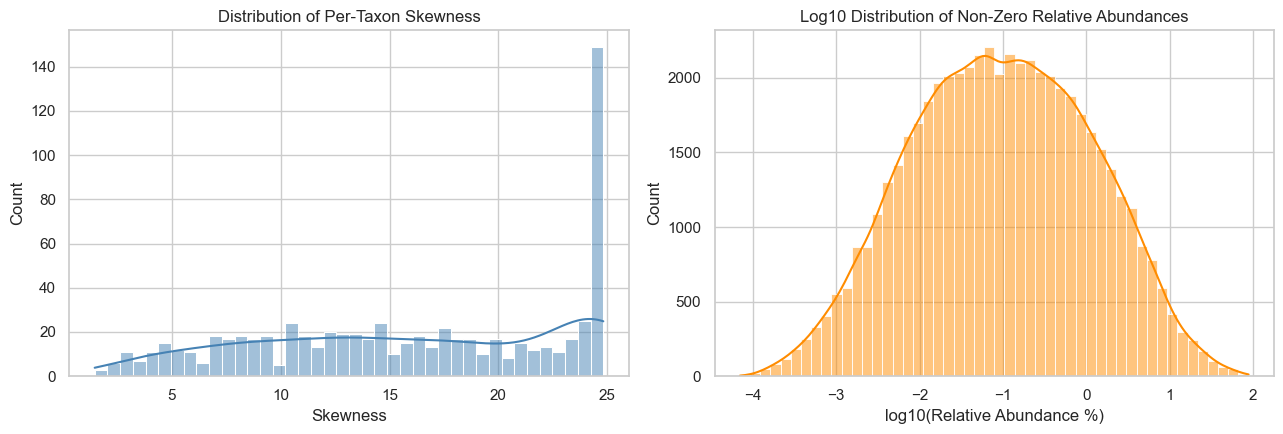

In [17]:
# Calculate sparsity (% of zero entries) and per-taxon skewness
zero_pct = (otu_616 == 0).sum().sum() / otu_616.size * 100
taxon_skewness = otu_616.skew(axis=1)

print(f"Matrix sparsity (zeros): {zero_pct:.2f}%")
print(f"Median taxon skewness:   {taxon_skewness.median():.2f} (Max: {taxon_skewness.max():.2f})")

# Plot skewness and log-transformed non-zero abundances
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Histogram of per-taxon skewness
sns.histplot(taxon_skewness.dropna(), bins=40, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of Per-Taxon Skewness")
axes[0].set_xlabel("Skewness")

# Raw vs Log10 non-zero abundance distribution
non_zero_vals = otu_616.values[otu_616.values > 0]
sns.histplot(np.log10(non_zero_vals), bins=50, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Log10 Distribution of Non-Zero Relative Abundances")
axes[1].set_xlabel("log10(Relative Abundance %)")

plt.tight_layout()
plt.show()


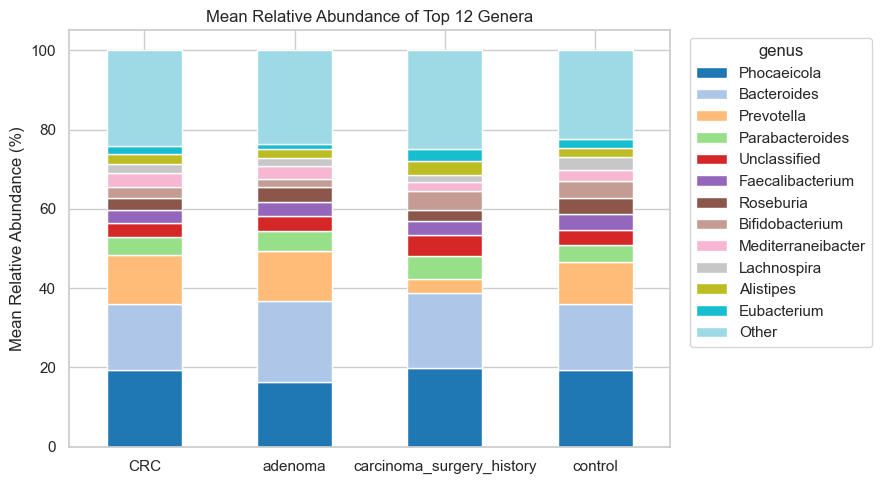

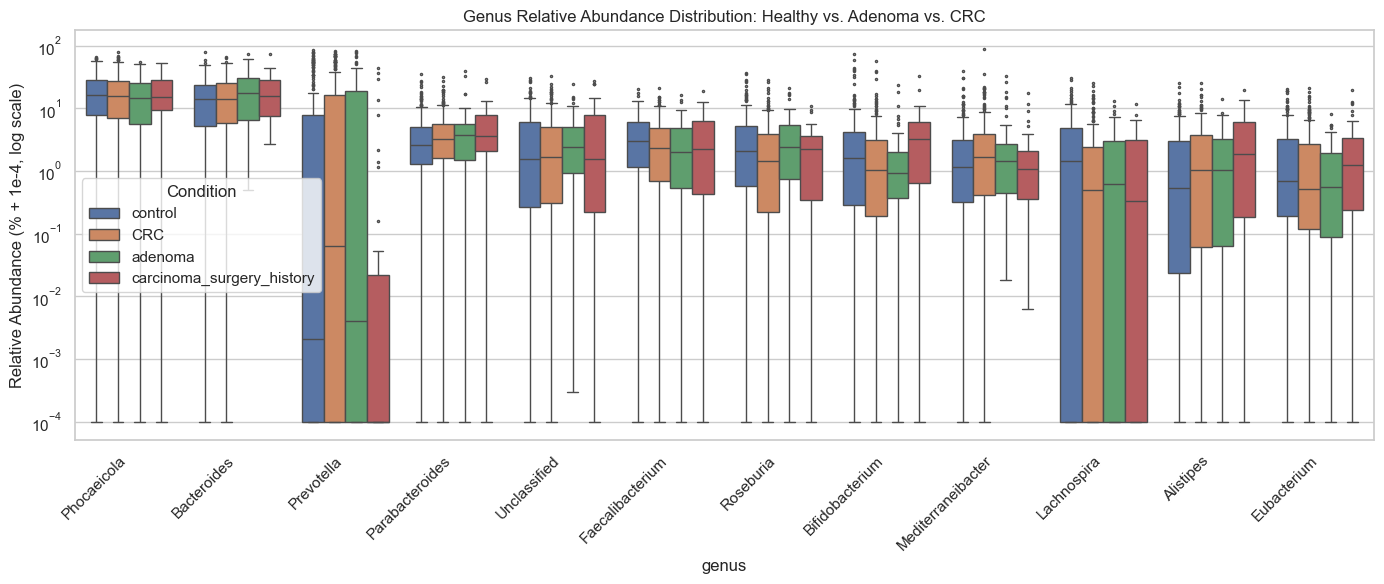

In [15]:
# 1. Aggregate OTU relative abundances by Genus
otu_genus = otu_616.copy()
otu_genus["genus"] = tax_table.loc[otu_genus.index, "genus"].fillna("Unclassified")
genus_df = otu_genus.groupby("genus").sum()  # Genera (rows) x Samples (cols)

# 2. Identify top 12 genera by overall mean relative abundance
top_genera = genus_df.mean(axis=1).sort_values(ascending=False).head(12).index
top_genus_df = genus_df.loc[top_genera].T  # Samples (rows) x Top Genera (cols)
top_genus_df["Condition"] = meta_616["study_condition"]

# Plot A: Mean Stacked Bar Chart by Condition
mean_comp = top_genus_df.groupby("Condition").mean()
mean_comp["Other"] = 100 - mean_comp.sum(axis=1)

ax = mean_comp.plot(kind="bar", stacked=True, figsize=(9, 5), colormap="tab20")
ax.set_title("Mean Relative Abundance of Top 12 Genera")
ax.set_ylabel("Mean Relative Abundance (%)")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="genus")
plt.tight_layout()
plt.show()

# Plot B: Boxplots of Top 12 Genera across Conditions (log-scaled y-axis for visibility)
melted = top_genus_df.melt(id_vars="Condition", var_name="genus", value_name="Abundance")
melted["Abundance_pseudocount"] = melted["Abundance"] + 1e-4  # Avoid log(0)

plt.figure(figsize=(14, 6))
sns.boxplot(
    data=melted, x="genus", y="Abundance_pseudocount", hue="Condition",
    fliersize=1.5
)
plt.yscale("log")
plt.xticks(rotation=45, ha="right")
plt.title("Genus Relative Abundance Distribution: Healthy vs. Adenoma vs. CRC")
plt.ylabel("Relative Abundance (% + 1e-4, log scale)")
plt.tight_layout()
plt.show()


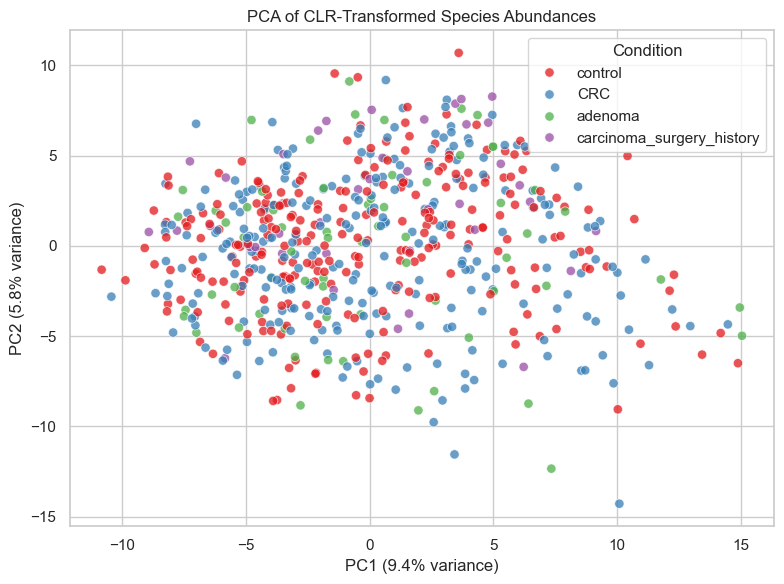

In [19]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Filter out ultra-rare taxa (present in < 5% of samples) to reduce noise
prevalence = (otu_616 > 0).mean(axis=1)
otu_filtered = otu_616.loc[prevalence >= 0.05].T  # Samples (rows) x Taxa (cols)

# 2. Apply Centered Log-Ratio (CLR) transformation
pseudocount = 1e-5
log_X = np.log(otu_filtered + pseudocount)
clr_X = log_X.sub(log_X.mean(axis=1), axis=0)

# 3. Standardize and run PCA
X_scaled = StandardScaler().fit_transform(clr_X)
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(coords, index=otu_filtered.index, columns=["PC1", "PC2"])
pca_df["Condition"] = meta_616.loc[pca_df.index, "study_condition"]
pca_df["Subtype"] = meta_616.loc[pca_df.index, "disease"]

# 4. Plot PCA colored by Study Condition
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=pca_df, x="PC1", y="PC2", hue="Condition",
    alpha=0.75, s=45, palette="Set1"
)
plt.title("PCA of CLR-Transformed Species Abundances")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.legend(title="Condition")
plt.tight_layout()
plt.show()


## Splitting data